# Seaborn for Data Visualization — Hands-on Guide

**Seaborn** is a statistical plotting library built on top of Matplotlib. It works directly with Pandas DataFrames, picks sensible colours and styles automatically, and does the statistics (means, confidence intervals, density curves, regression lines) for you.

**Contents**
1. Importing Seaborn & creating data
2. Themes, styles and palettes
3. Axes-level vs figure-level functions (important concept)
4. Distribution plots — `histplot`, `kdeplot`, `ecdfplot`, `displot`
5. Categorical plots — `countplot`, `barplot`, `boxplot`, `violinplot`, `stripplot`, `swarmplot`, `pointplot`, `catplot`
6. Relational plots — `scatterplot`, `lineplot`, `relplot`
7. Regression plots — `regplot`, `lmplot`, `residplot`
8. Matrix plots — `heatmap`, `clustermap`
9. Multi-variable plots — `pairplot`, `jointplot`
10. Customising plots — titles, labels, size, subplots, annotations
11. Saving figures
12. Choosing the right plot (cheat sheet)
13. Practice exercises

We use a simulated **loan portfolio** dataset (500 loans) so the examples feel realistic.

## 1. Importing Seaborn

- Convention: `import seaborn as sns`
- Seaborn draws on **Matplotlib**, so we import `matplotlib.pyplot as plt` to control titles, sizes and saving
- `%matplotlib inline` makes plots appear inside the notebook (default in modern Jupyter)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

print("Seaborn version:", sns.__version__)

Seaborn version: 0.13.2


### 1.1 Creating the dataset

Seaborn also ships sample datasets (`sns.load_dataset("tips")`, `"titanic"`, `"iris"`…), but these need an internet connection. We generate our own data so the notebook runs offline.

Seaborn works best with **tidy (long) data**: one row per observation, one column per variable.

In [2]:
rng = np.random.default_rng(42)
n = 500

branches = rng.choice(["Dhaka", "Chattogram", "Sylhet", "Khulna"], n, p=[0.4, 0.25, 0.15, 0.2])
sectors  = rng.choice(["Trading", "Manufacturing", "Service", "Agriculture"], n)
gender   = rng.choice(["Male", "Female"], n, p=[0.65, 0.35])

loan_amount   = np.round(rng.lognormal(mean=13, sigma=0.6, size=n), -3)       # BDT
credit_score  = rng.normal(680, 60, n).clip(450, 850).round()
tenure_months = rng.choice([12, 24, 36, 48, 60], n)

# Lower credit score -> more overdue days (with noise)
overdue_days = np.maximum(0, (720 - credit_score) * 1.2 + rng.normal(0, 40, n)).round()
repaid_pct   = np.clip(100 - overdue_days * 0.25 + rng.normal(0, 8, n), 0, 100).round(1)
outstanding  = (loan_amount * (1 - repaid_pct / 100)).round()

month = rng.choice(pd.period_range("2025-01", "2025-12", freq="M").astype(str), n)

df = pd.DataFrame({
    "branch": branches, "sector": sectors, "gender": gender,
    "loan_amount": loan_amount, "outstanding": outstanding,
    "credit_score": credit_score, "tenure_months": tenure_months,
    "overdue_days": overdue_days, "repaid_pct": repaid_pct, "month": month,
})

df["classification"] = np.select(
    [df["overdue_days"] == 0, df["overdue_days"] <= 60, df["overdue_days"] <= 180],
    ["Standard", "SMA", "Substandard"], default="Bad/Loss",
)
df["is_npl"] = np.where(df["overdue_days"] > 90, "NPL", "Performing")
df["loan_lakh"] = df["loan_amount"] / 100_000
df = df.sort_values("month").reset_index(drop=True)   # time order matters for line plots

class_order = ["Standard", "SMA", "Substandard", "Bad/Loss"]
df.head()

,branch,sector,gender,loan_amount,outstanding,credit_score,tenure_months,overdue_days,repaid_pct,month,classification,is_npl,loan_lakh
0,Dhaka,Service,Female,429000.0,26169.0,617.0,24,100.0,93.9,2025-01,Substandard,NPL,4.29
1,Chattogram,Agriculture,Male,549000.0,74115.0,686.0,48,31.0,86.5,2025-01,SMA,Performing,5.49
2,Dhaka,Service,Male,572000.0,188760.0,681.0,12,103.0,67.0,2025-01,Substandard,NPL,5.72
3,Khulna,Manufacturing,Male,312000.0,0.0,717.0,36,0.0,100.0,2025-01,Standard,Performing,3.12
4,Khulna,Manufacturing,Female,310000.0,0.0,800.0,24,0.0,100.0,2025-01,Standard,Performing,3.10


In [3]:
df.describe().round(1)

,loan_amount,outstanding,credit_score,tenure_months,overdue_days,repaid_pct,loan_lakh
count,500.0,500.0,500.0,500.0,500.0,500.0,500.0
mean,515034.0,92844.8,675.2,35.9,67.5,82.2,5.2
std,341382.7,122003.2,58.1,17.5,64.2,16.2,3.4
min,75000.0,0.0,497.0,12.0,0.0,24.4,0.8
25%,286000.0,12624.2,634.8,24.0,0.0,71.7,2.9
50%,436000.0,54900.0,679.5,36.0,58.5,85.2,4.4
75%,640250.0,131084.0,715.0,48.0,111.0,96.7,6.4
max,2542000.0,1337364.0,850.0,60.0,281.0,100.0,25.4


## 2. Themes, Styles and Palettes

`sns.set_theme()` applies Seaborn's look to **all** following plots.

| Setting | Options | Controls |
|---|---|---|
| `style` | `darkgrid` (default), `whitegrid`, `dark`, `white`, `ticks` | Background & grid |
| `context` | `paper`, `notebook` (default), `talk`, `poster` | Scale of fonts/lines (use `talk` for slides) |
| `palette` | `deep`, `muted`, `pastel`, `bright`, `dark`, `colorblind`, `viridis`, `Blues`… | Colours |

**Palette types**
- **Qualitative** (`deep`, `Set2`, `colorblind`) → categories with no order
- **Sequential** (`Blues`, `viridis`, `rocket`) → low → high values
- **Diverging** (`coolwarm`, `RdBu`, `vlag`) → values around a midpoint (e.g. correlation)

In [4]:
# Preview palettes
for name in ["deep", "colorblind", "Blues", "coolwarm"]:
    print(name)
    display(sns.color_palette(name, 6))

deep


[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941)]

colorblind


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451)]

Blues


[(0.8584083044982699, 0.9134486735870818, 0.9645674740484429),
 (0.7309496347558632, 0.8394771241830065, 0.9213225682429834),
 (0.5356862745098039, 0.746082276047674, 0.8642522106881968),
 (0.32628988850442137, 0.6186236063052672, 0.802798923490965),
 (0.16696655132641292, 0.48069204152249134, 0.7291503267973857),
 (0.044059976931949255, 0.3338869665513264, 0.6244521337946944)]

coolwarm


[(0.4044212904941176, 0.5346434904470588, 0.9320019126352941),
 (0.603162067917647, 0.7315274773529412, 0.9995652785372549),
 (0.7867207013568628, 0.8448072103686275, 0.9398103849490196),
 (0.9306685963333333, 0.818876999654902, 0.7591463906980392),
 (0.9673165156666667, 0.6574708288078431, 0.5381601507294118),
 (0.8846434386941177, 0.41001709788235297, 0.32250654924705885)]

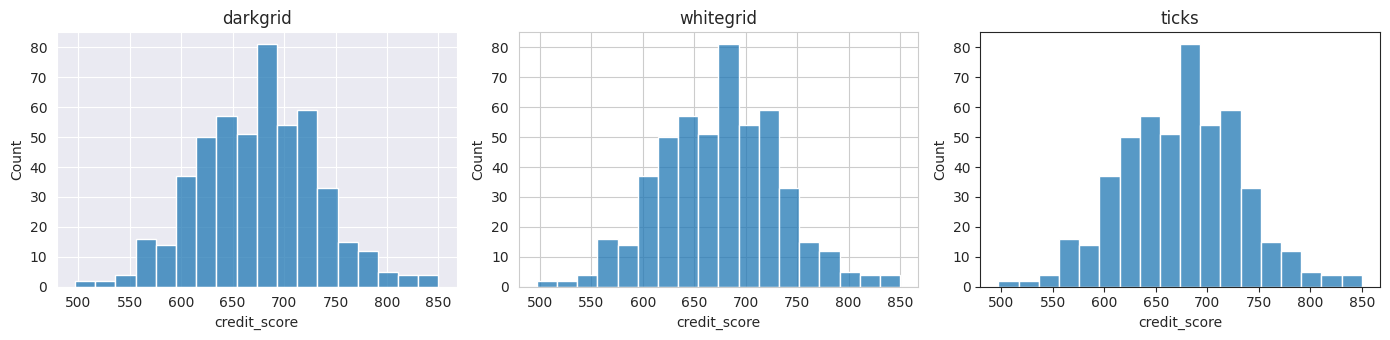

In [5]:
# Compare styles
fig = plt.figure(figsize=(14, 3.5))
for i, style in enumerate(["darkgrid", "whitegrid", "ticks"], start=1):
    with sns.axes_style(style):          # style applies only inside this block
        ax = fig.add_subplot(1, 3, i)
        sns.histplot(df["credit_score"], ax=ax)
        ax.set_title(style)
plt.tight_layout()

In [6]:
# Set the theme used for the rest of the notebook
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

## 3. Axes-level vs Figure-level Functions

This is the **most important concept** in Seaborn — it explains why some plots accept `ax=` and others don't.

| | Axes-level | Figure-level |
|---|---|---|
| Examples | `histplot`, `scatterplot`, `boxplot`, `heatmap` | `displot`, `relplot`, `catplot`, `lmplot`, `pairplot`, `jointplot` |
| Draws on | One Matplotlib `Axes` | Its own whole figure |
| Place in subplots? | ✅ Yes, with `ax=` | ❌ No |
| Size control | `plt.figure(figsize=…)` or `plt.subplots` | `height=` and `aspect=` |
| Small multiples | Manual | Built in: `col=`, `row=` |

Each figure-level function wraps a family of axes-level functions via `kind=`:

- `displot(kind="hist" | "kde" | "ecdf")`
- `relplot(kind="scatter" | "line")`
- `catplot(kind="strip" | "swarm" | "box" | "violin" | "bar" | "count" | "point")`

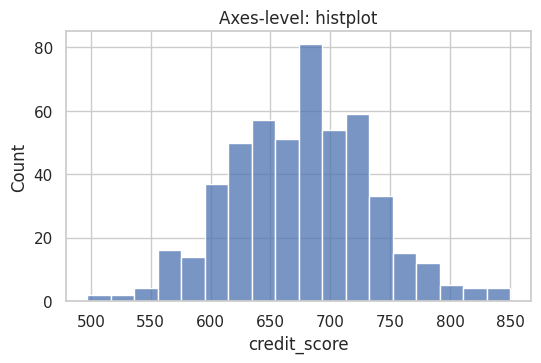

In [7]:
# Axes-level: you control the figure
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(data=df, x="credit_score", ax=ax)
ax.set_title("Axes-level: histplot");

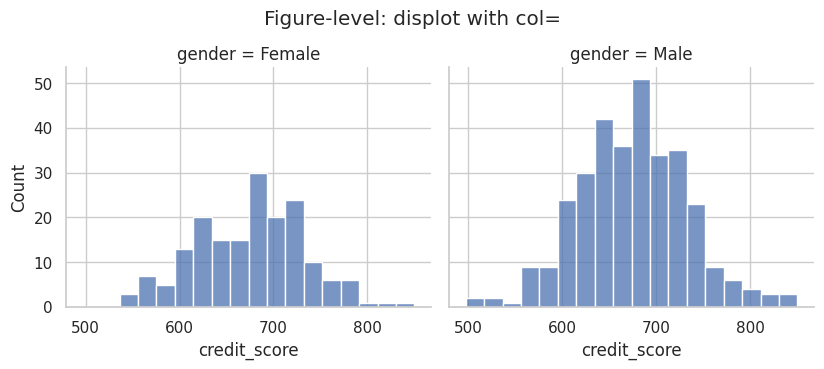

In [8]:
# Figure-level: Seaborn creates the figure; col= splits into panels automatically
g = sns.displot(data=df, x="credit_score", col="gender", height=3.5, aspect=1.2)
g.figure.suptitle("Figure-level: displot with col=", y=1.05);

## 4. Distribution Plots

Use these to answer: *What values are common? Is the data skewed? Are there outliers?*

### 4.1 `histplot()` — Histogram

Counts how many values fall into each bin.

| Parameter | Effect |
|---|---|
| `bins=` / `binwidth=` | Number of bins / width of each bin |
| `kde=True` | Overlay a smooth density curve |
| `hue=` | Split by a category |
| `multiple=` | `"layer"`, `"stack"`, `"dodge"`, `"fill"` — how hue groups are combined |
| `stat=` | `"count"`, `"percent"`, `"density"`, `"probability"` |
| `log_scale=True` | Log axis — useful for skewed money values |

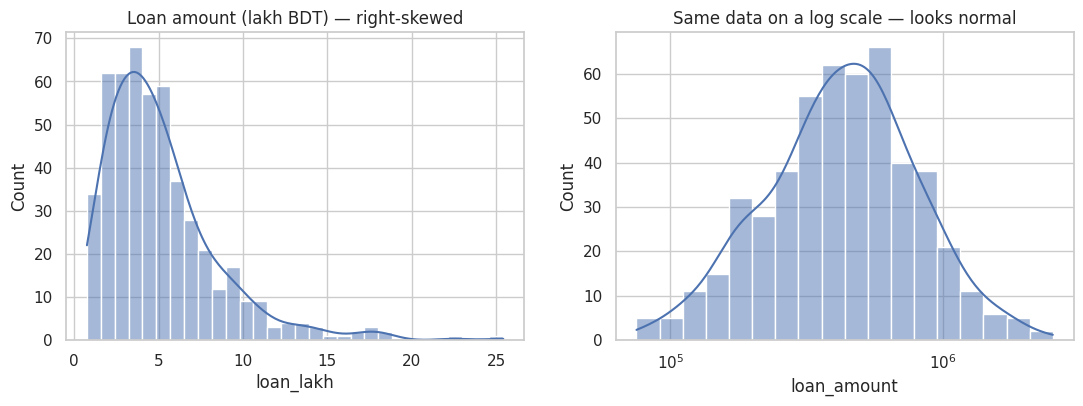

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=df, x="loan_lakh", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Loan amount (lakh BDT) — right-skewed")

sns.histplot(data=df, x="loan_amount", log_scale=True, kde=True, ax=axes[1])
axes[1].set_title("Same data on a log scale — looks normal");

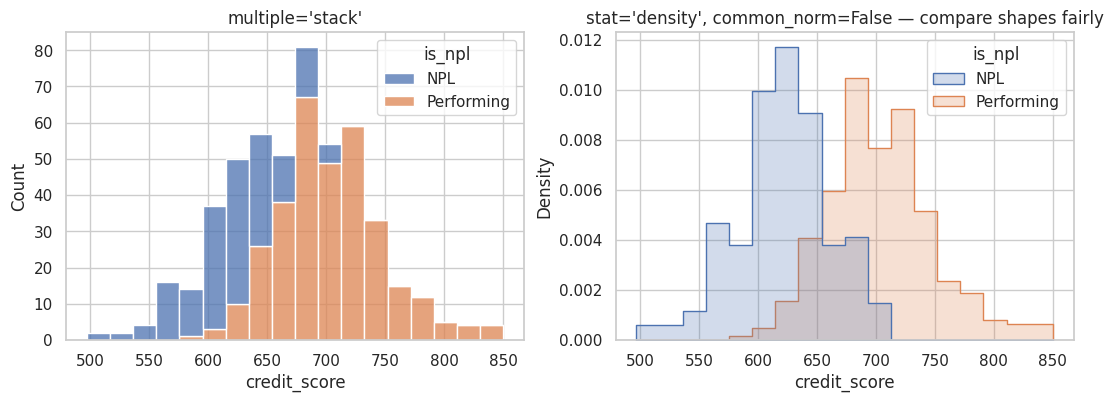

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=df, x="credit_score", hue="is_npl", multiple="stack", ax=axes[0])
axes[0].set_title("multiple='stack'")

sns.histplot(data=df, x="credit_score", hue="is_npl", stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("stat='density', common_norm=False — compare shapes fairly");

### 4.2 `kdeplot()` — Kernel Density Estimate

A smoothed version of the histogram. Good for **comparing the shape** of several groups on one plot.

- `fill=True` shades the area under the curve
- `bw_adjust=` controls smoothness (<1 = more detail, >1 = smoother)
- Pass both `x=` and `y=` for a 2-D density

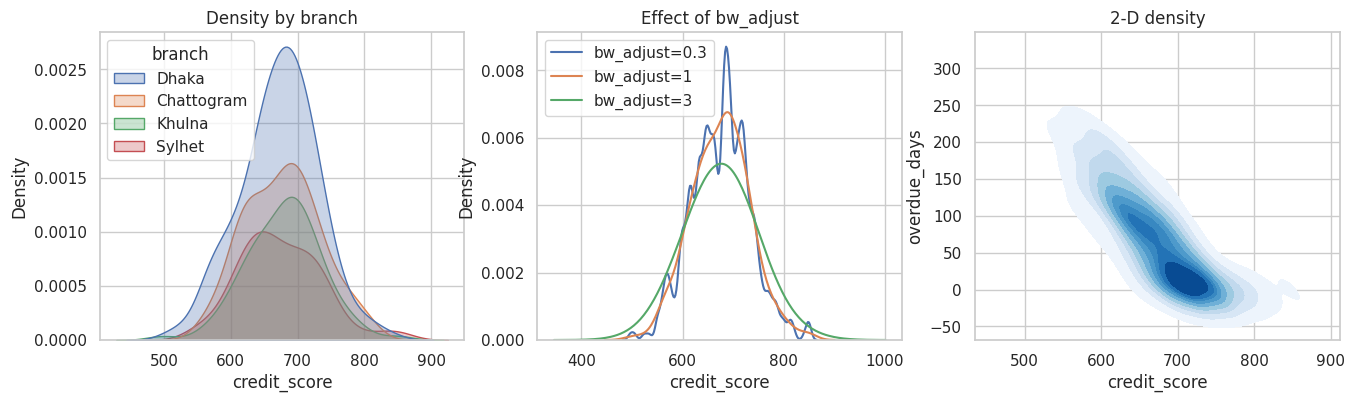

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.kdeplot(data=df, x="credit_score", hue="branch", fill=True, alpha=0.3, ax=axes[0])
axes[0].set_title("Density by branch")

for bw in [0.3, 1, 3]:
    sns.kdeplot(data=df, x="credit_score", bw_adjust=bw, label=f"bw_adjust={bw}", ax=axes[1])
axes[1].legend(); axes[1].set_title("Effect of bw_adjust")

sns.kdeplot(data=df, x="credit_score", y="overdue_days", fill=True, cmap="Blues", ax=axes[2])
axes[2].set_title("2-D density");

### 4.3 `ecdfplot()` — Empirical Cumulative Distribution

Shows the **proportion of data at or below each value**. No bins to choose, and percentiles are easy to read.

*Example read-out: "about 60% of loans have 0 overdue days".*

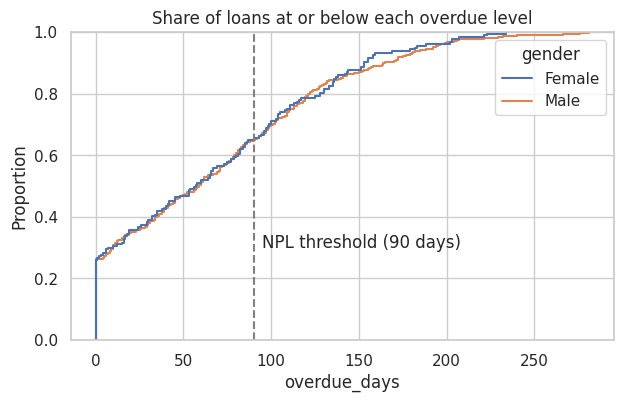

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.ecdfplot(data=df, x="overdue_days", hue="gender", ax=ax)
ax.axvline(90, ls="--", color="gray")
ax.text(95, 0.3, "NPL threshold (90 days)")
ax.set_title("Share of loans at or below each overdue level");

### 4.4 `displot()` — Figure-level Distribution

Same as the above, plus `col=` / `row=` for small multiples.

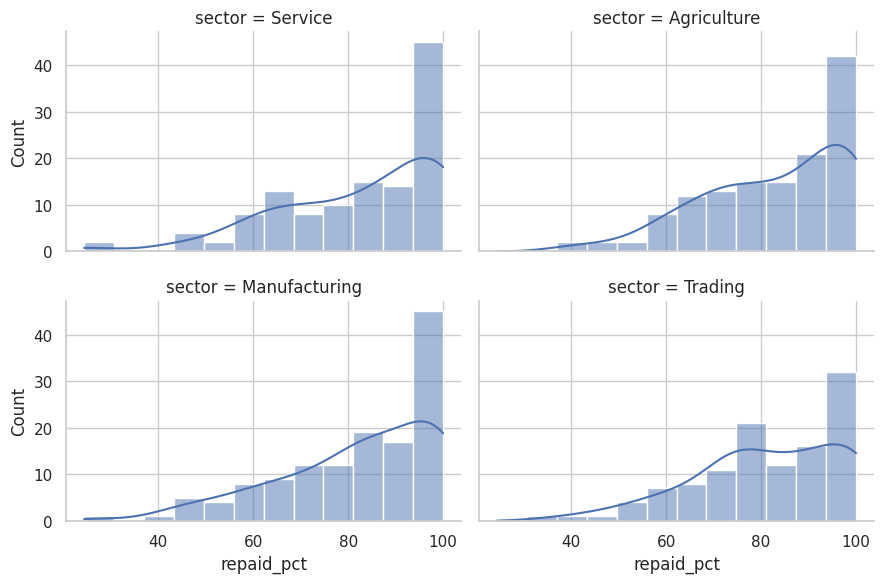

In [13]:
sns.displot(data=df, x="repaid_pct", col="sector", col_wrap=2,
            kde=True, height=3, aspect=1.5);

## 5. Categorical Plots

Use these when one axis is a **category** (branch, sector, classification).

| Group | Functions | Shows |
|---|---|---|
| Counts | `countplot` | How many rows in each category |
| Estimates | `barplot`, `pointplot` | Mean (or other statistic) + confidence interval |
| Distributions | `boxplot`, `violinplot`, `boxenplot` | Spread, median, outliers |
| Every point | `stripplot`, `swarmplot` | Each observation |

💡 Use `order=` to control category order and `orient="h"` / swap x & y for horizontal bars (helpful with long labels).

### 5.1 `countplot()` — Frequency of Categories

The visual version of `value_counts()`.

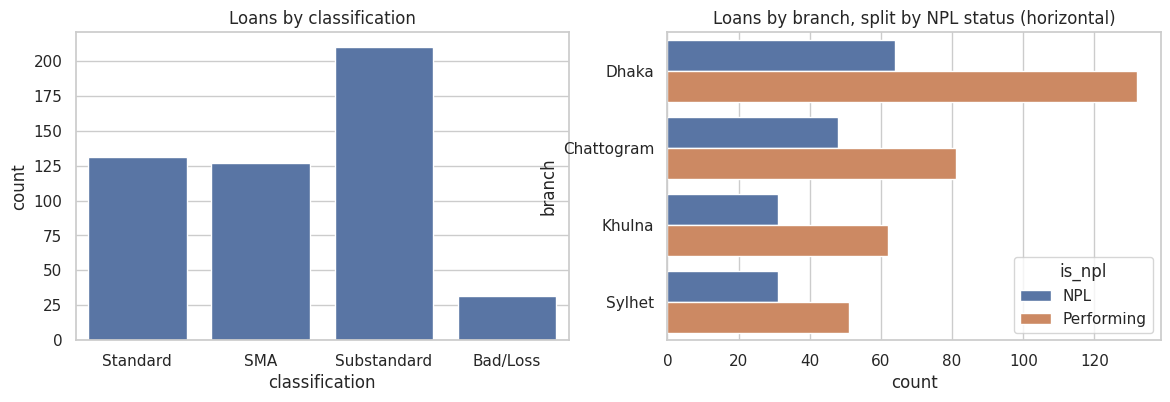

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(data=df, x="classification", order=class_order, ax=axes[0])
axes[0].set_title("Loans by classification")

sns.countplot(data=df, y="branch", hue="is_npl",
              order=df["branch"].value_counts().index, ax=axes[1])
axes[1].set_title("Loans by branch, split by NPL status (horizontal)");

### 5.2 `barplot()` — Mean (or other statistic) by Category

⚠️ `barplot` does **not** show counts — it shows an **estimate** (mean by default) with an error bar.

| Parameter | Effect |
|---|---|
| `estimator=` | `"mean"` (default), `"sum"`, `"median"`, `np.max`… |
| `errorbar=` | `("ci", 95)` default, `"sd"`, `"se"`, or `None` |
| `hue=` | Grouped bars |

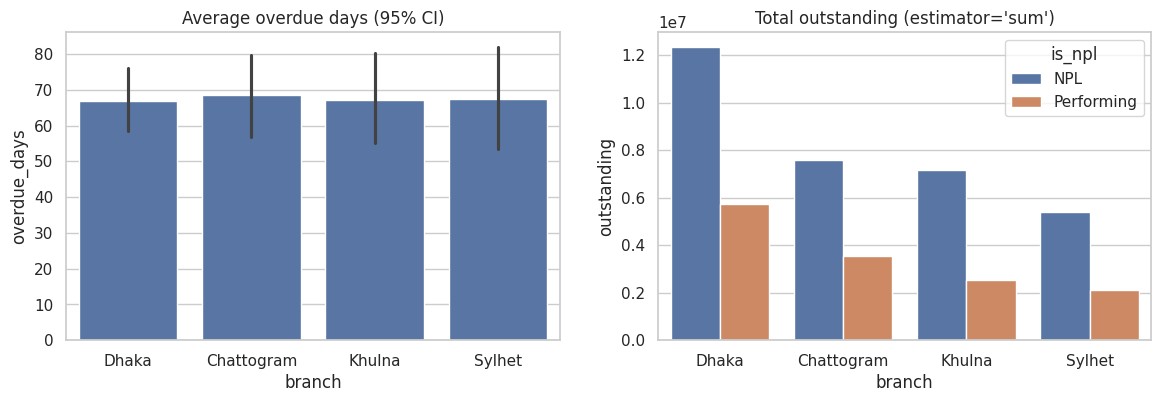

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df, x="branch", y="overdue_days", errorbar=("ci", 95), ax=axes[0])
axes[0].set_title("Average overdue days (95% CI)")

sns.barplot(data=df, x="branch", y="outstanding", hue="is_npl",
            estimator="sum", errorbar=None, ax=axes[1])
axes[1].set_title("Total outstanding (estimator='sum')");

### 5.3 `boxplot()` — Five-number Summary

The box shows the **25th–75th percentile (IQR)**, the line is the **median**, whiskers extend to 1.5 × IQR, and dots beyond are **outliers**.

```
   o          <- outlier
   |          <- whisker (max within 1.5×IQR)
 ┌───┐        <- Q3 (75th percentile)
 │───│        <- median
 └───┘        <- Q1 (25th percentile)
   |          <- whisker
```

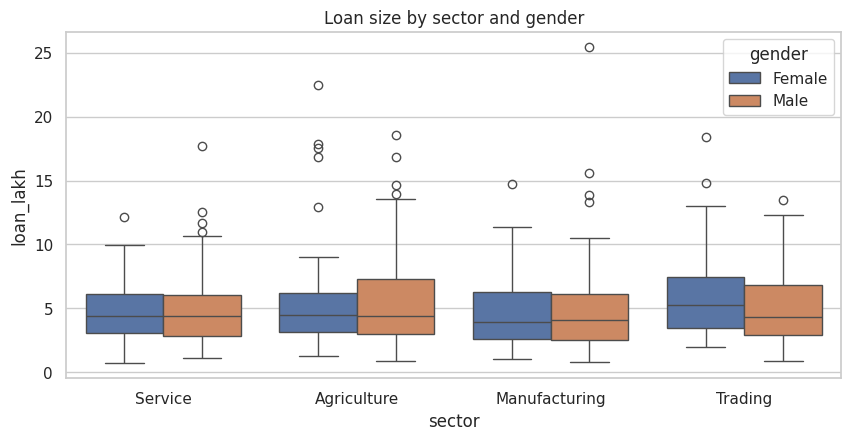

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="sector", y="loan_lakh", hue="gender", ax=ax)
ax.set_title("Loan size by sector and gender");

### 5.4 `violinplot()` — Box plot + Density

Shows the full **shape** of the distribution (e.g. two peaks), which a box plot hides.

- `split=True` with a two-level `hue` puts one group on each side
- `inner="quart"` draws quartile lines inside

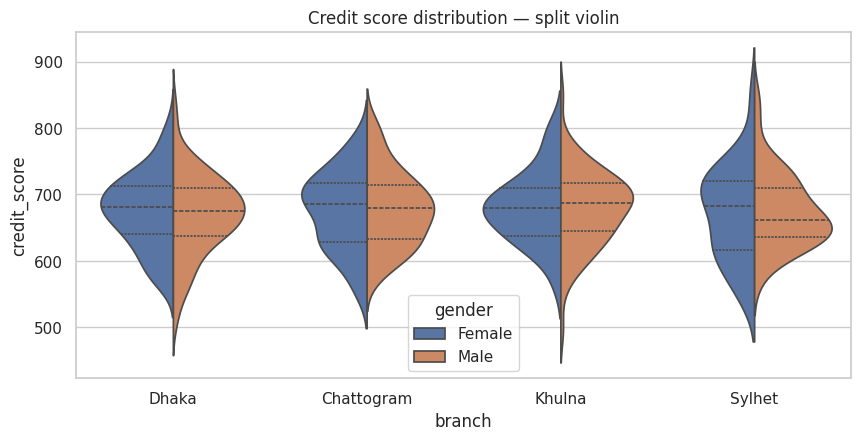

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.violinplot(data=df, x="branch", y="credit_score", hue="gender",
               split=True, inner="quart", ax=ax)
ax.set_title("Credit score distribution — split violin");

### 5.5 `stripplot()` and `swarmplot()` — Every Observation

- `stripplot` — random horizontal **jitter** to reduce overlap (fast, any size)
- `swarmplot` — arranges points so **none overlap** (slow on large data; best under ~1,000 points)

Tip: overlay them on a box/violin plot to show both the summary and the raw data.

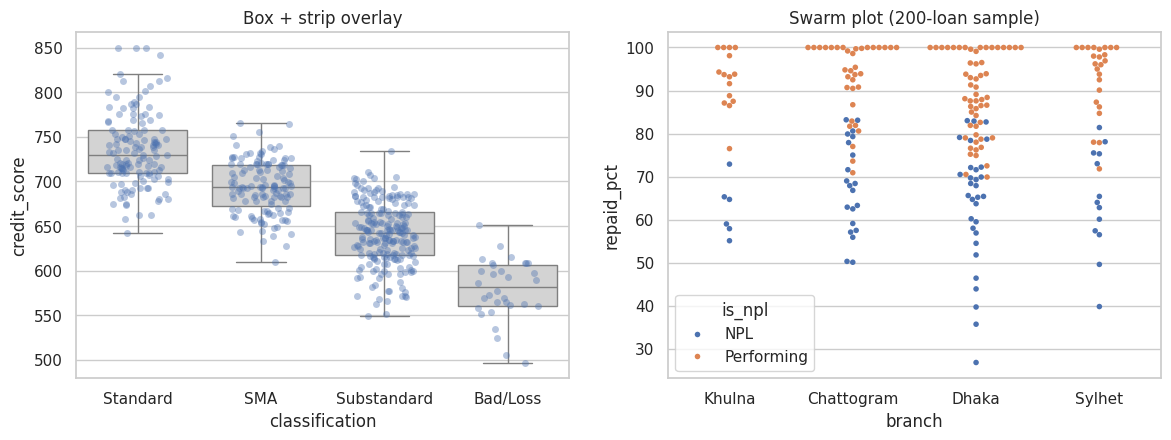

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=df, x="classification", y="credit_score", order=class_order,
            color="lightgray", showfliers=False, ax=axes[0])
sns.stripplot(data=df, x="classification", y="credit_score", order=class_order,
              alpha=0.4, jitter=0.25, ax=axes[0])
axes[0].set_title("Box + strip overlay")

sample = df.sample(200, random_state=1)
sns.swarmplot(data=sample, x="branch", y="repaid_pct", hue="is_npl", size=4, ax=axes[1])
axes[1].set_title("Swarm plot (200-loan sample)");

### 5.6 `pointplot()` — Compare Means Across Groups

Draws the mean as a point with an error bar, connected by lines. Great for spotting **interactions** (does the gap between groups change across categories?).

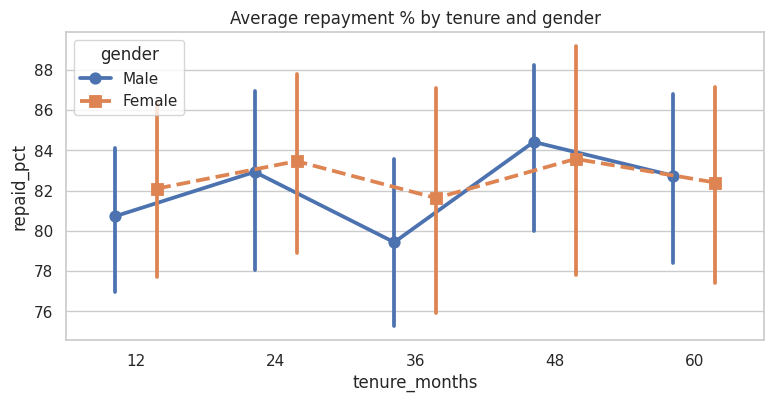

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.pointplot(data=df, x="tenure_months", y="repaid_pct", hue="gender",
              dodge=0.3, markers=["o", "s"], linestyles=["-", "--"], ax=ax)
ax.set_title("Average repayment % by tenure and gender");

### 5.7 `catplot()` — Figure-level Categorical

Any categorical plot via `kind=`, with `col=` / `row=` facets.

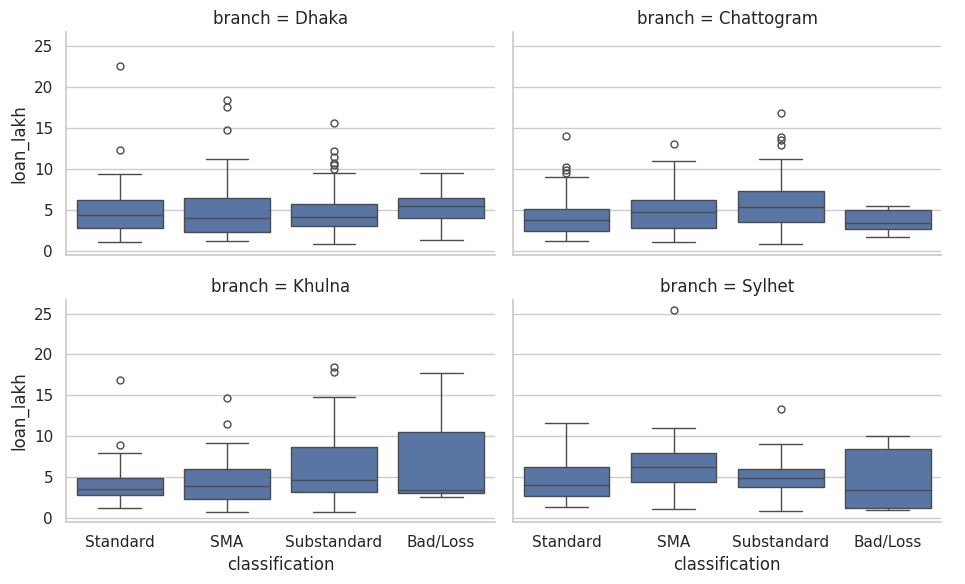

In [20]:
sns.catplot(data=df, x="classification", y="loan_lakh", col="branch", col_wrap=2,
            kind="box", order=class_order, height=3, aspect=1.6);

## 6. Relational Plots

Show the relationship between **two numeric variables**.

### 6.1 `scatterplot()`

Map extra variables to visual properties:

| Parameter | Encodes a variable as |
|---|---|
| `hue=` | Colour |
| `size=` | Point size |
| `style=` | Marker shape |
| `alpha=` | Transparency (use for dense data) |

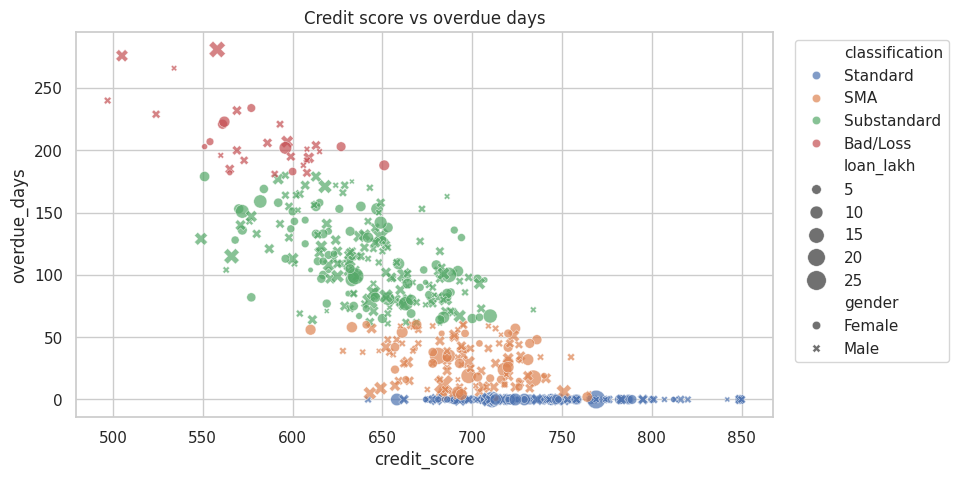

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="credit_score", y="overdue_days",
                hue="classification", hue_order=class_order,
                size="loan_lakh", sizes=(15, 200),
                style="gender", alpha=0.7, ax=ax)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Credit score vs overdue days");

### 6.2 `lineplot()`

Best for **trends over time** or an ordered x-axis. When several rows share the same x value, Seaborn automatically plots the **mean** with a **95% confidence band**.

- `estimator=` to change the statistic (`"sum"`, `"median"`)
- `errorbar=None` to remove the band
- `marker="o"` to show the points

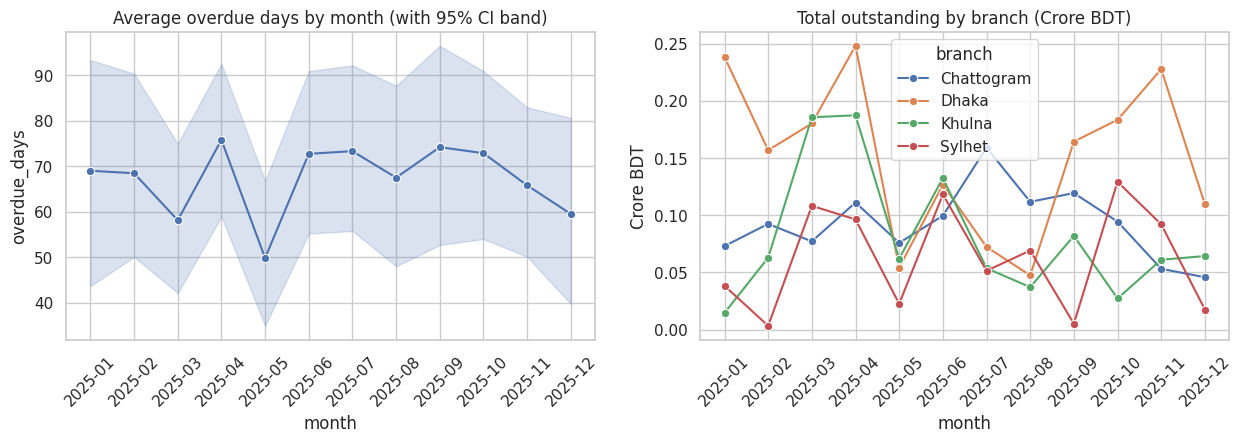

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.lineplot(data=df, x="month", y="overdue_days", marker="o", ax=axes[0])
axes[0].set_title("Average overdue days by month (with 95% CI band)")
axes[0].tick_params(axis="x", rotation=45)

monthly = df.groupby(["month", "branch"], as_index=False)["outstanding"].sum()
monthly["outstanding_cr"] = monthly["outstanding"] / 1e7
sns.lineplot(data=monthly, x="month", y="outstanding_cr", hue="branch", marker="o", ax=axes[1])
axes[1].set(title="Total outstanding by branch (Crore BDT)", ylabel="Crore BDT")
axes[1].tick_params(axis="x", rotation=45);

### 6.3 `relplot()` — Figure-level Relational

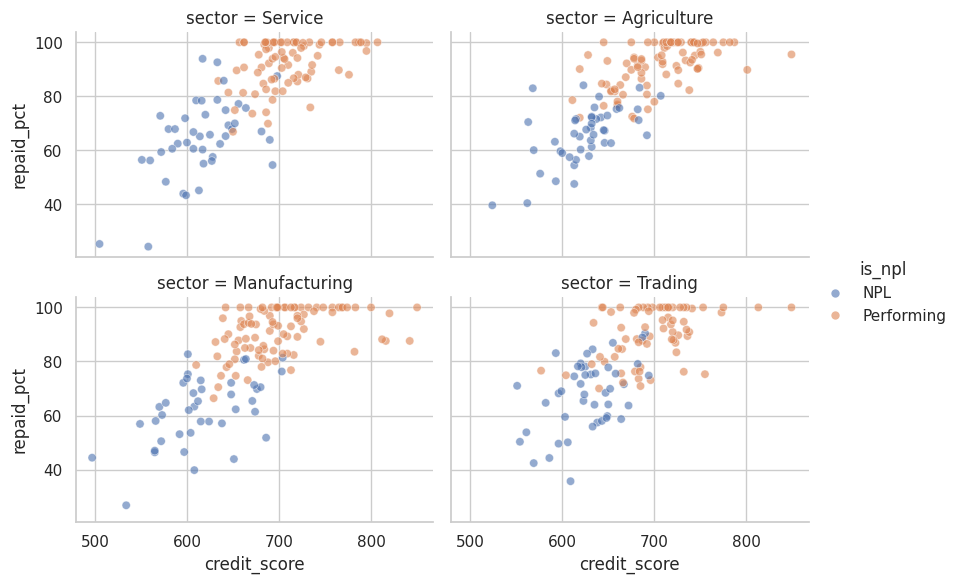

In [23]:
sns.relplot(data=df, x="credit_score", y="repaid_pct", hue="is_npl",
            col="sector", col_wrap=2, height=3, aspect=1.4, alpha=0.6);

## 7. Regression Plots

Add a fitted line to check whether two variables are linearly related.

| Function | Level | Notes |
|---|---|---|
| `regplot()` | Axes | Scatter + regression line + confidence band |
| `lmplot()` | Figure | Same, plus `hue=` and `col=` for separate fits per group |
| `residplot()` | Axes | Residuals — a random cloud around 0 means a linear fit is OK |

Useful options: `order=2` (polynomial), `lowess=True` (flexible smooth curve — needs `pip install statsmodels`), `logistic=True` (0/1 outcome — needs statsmodels), `x_bins=` (plot binned means), `scatter_kws` / `line_kws` for styling.

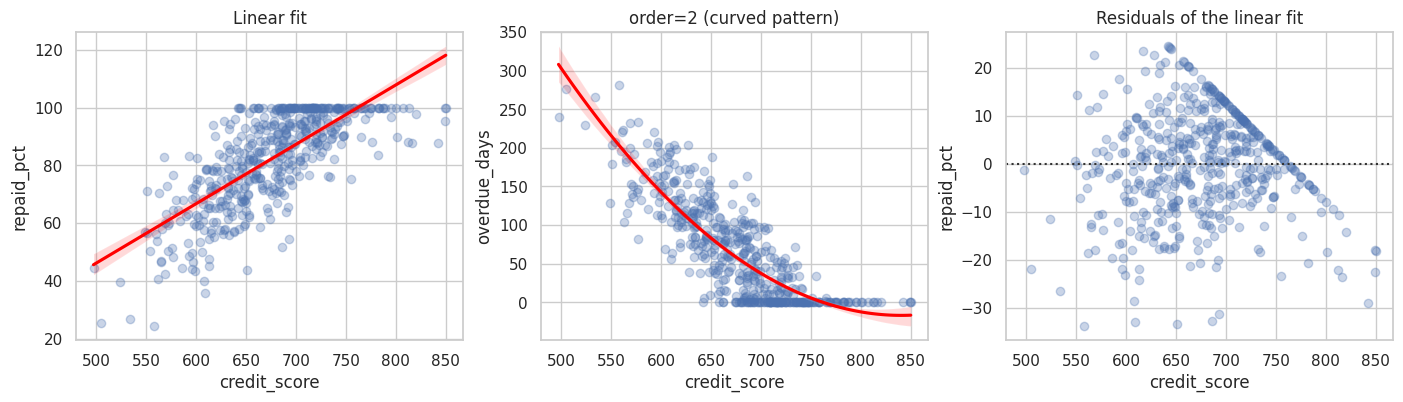

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.regplot(data=df, x="credit_score", y="repaid_pct",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Linear fit")

sns.regplot(data=df, x="credit_score", y="overdue_days", order=2,
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("order=2 (curved pattern)")

sns.residplot(data=df, x="credit_score", y="repaid_pct",
              scatter_kws={"alpha": 0.3}, ax=axes[2])
axes[2].set_title("Residuals of the linear fit");

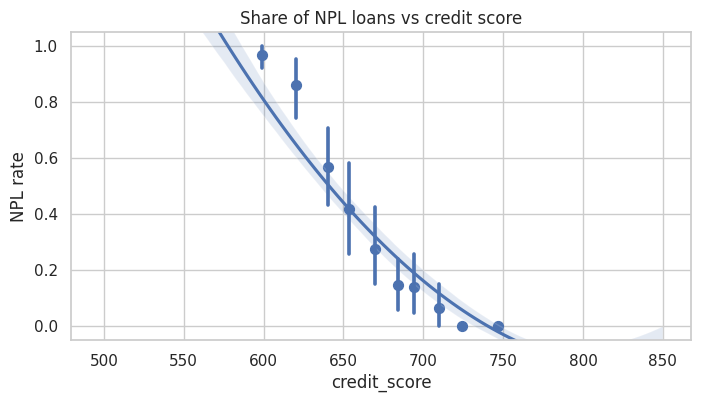

In [25]:
# NPL probability by credit score band (x_bins groups x and plots the mean y per bin)
# Tip: with statsmodels installed, logistic=True fits an S-shaped logistic curve instead
df["npl_flag"] = (df["is_npl"] == "NPL").astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
sns.regplot(data=df, x="credit_score", y="npl_flag", x_bins=10, order=2,
            truncate=True, ax=ax)
ax.set(title="Share of NPL loans vs credit score", ylabel="NPL rate", ylim=(-0.05, 1.05));

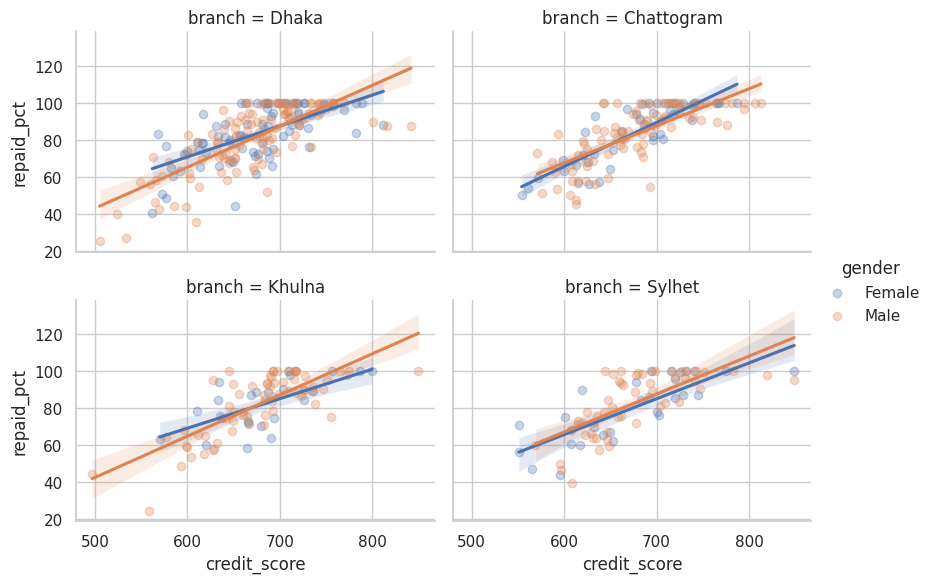

In [26]:
# lmplot: separate regression line per group
sns.lmplot(data=df, x="credit_score", y="repaid_pct", hue="gender",
           col="branch", col_wrap=2, height=3, aspect=1.4,
           scatter_kws={"alpha": 0.3});

## 8. Matrix Plots

Plot a **2-D table** of numbers as a colour grid.

### 8.1 `heatmap()`

Two common uses:
1. **Correlation matrix** → which numeric variables move together
2. **Pivot table** → a summary grid (like Excel conditional formatting)

| Parameter | Effect |
|---|---|
| `annot=True` | Write the number in each cell |
| `fmt=` | Number format, e.g. `".2f"`, `",.0f"`, `".1%"` |
| `cmap=` | Colour map (`"coolwarm"` for correlations, `"Blues"` for amounts) |
| `vmin=`, `vmax=`, `center=` | Fix the colour scale |
| `mask=` | Hide cells (e.g. the upper triangle) |
| `linewidths=` | Gap between cells |

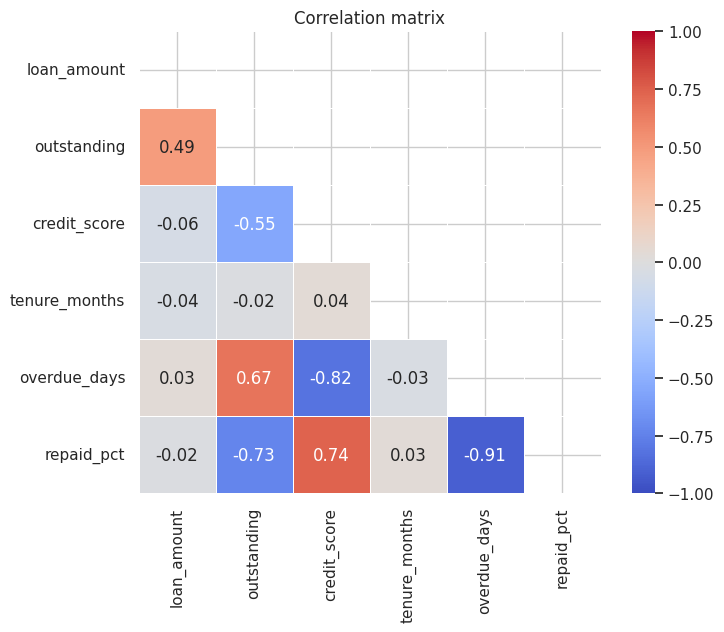

In [27]:
corr = df[["loan_amount", "outstanding", "credit_score", "tenure_months",
           "overdue_days", "repaid_pct"]].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))    # hide upper triangle (duplicate info)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, linewidths=0.5, square=True, ax=ax)
ax.set_title("Correlation matrix");

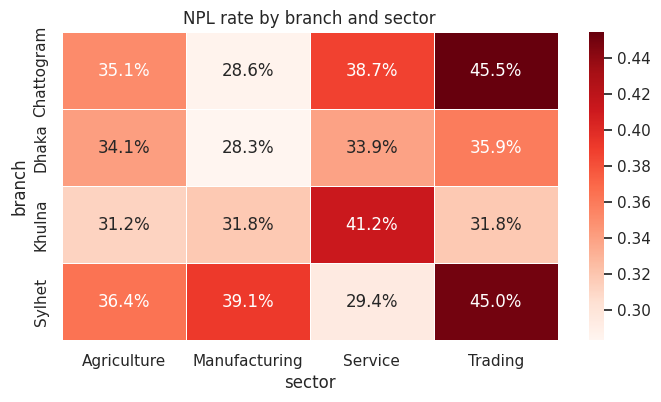

In [28]:
# Heatmap of a pivot table: NPL rate by branch x sector
npl_rate = pd.pivot_table(df, index="branch", columns="sector",
                          values="npl_flag", aggfunc="mean")

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(npl_rate, annot=True, fmt=".1%", cmap="Reds", linewidths=0.5, ax=ax)
ax.set_title("NPL rate by branch and sector");

### 8.2 `clustermap()`

A heatmap that **reorders rows and columns** so similar ones sit together (hierarchical clustering). `standard_scale=1` scales each column to 0–1 so different units can be compared.

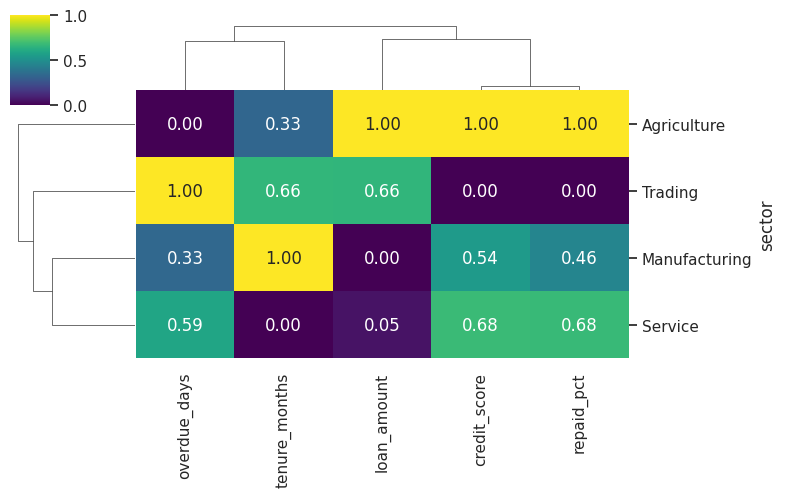

In [29]:
profile = df.groupby("sector")[["loan_amount", "credit_score", "overdue_days",
                                "repaid_pct", "tenure_months"]].mean()
sns.clustermap(profile, standard_scale=1, cmap="viridis", annot=True, fmt=".2f",
               figsize=(8, 5));

## 9. Multi-variable Plots

### 9.1 `pairplot()` — Every Pair at Once

A grid of scatter plots for every pair of numeric columns, with distributions on the diagonal. A fast first step in **EDA**.

- `vars=` choose columns
- `hue=` colour by category
- `diag_kind=` `"hist"` or `"kde"`
- `corner=True` show only the lower triangle

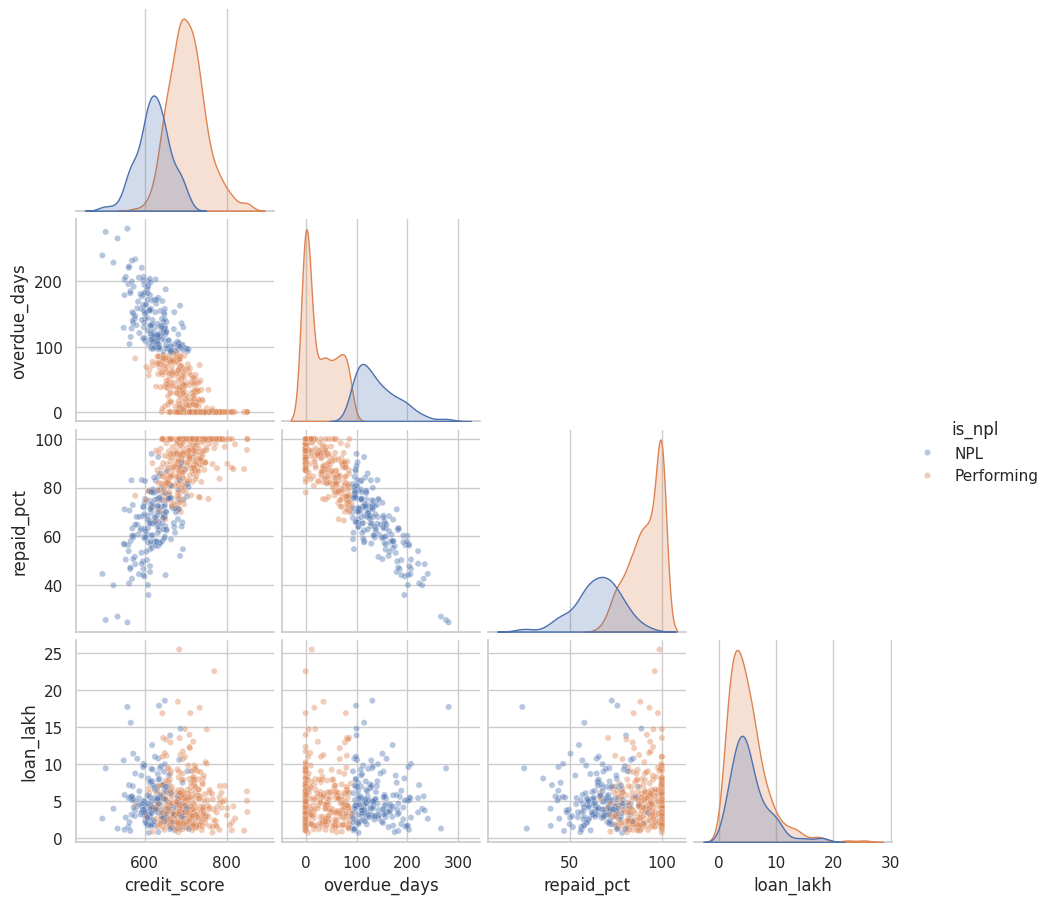

In [30]:
sns.pairplot(df, vars=["credit_score", "overdue_days", "repaid_pct", "loan_lakh"],
             hue="is_npl", diag_kind="kde", corner=True,
             plot_kws={"alpha": 0.4, "s": 20}, height=2.3);

### 9.2 `jointplot()` — Two Variables + Their Distributions

The main plot in the centre with each variable's distribution on the margins.

`kind=`: `"scatter"` (default), `"kde"`, `"hist"`, `"hex"` (for many points), `"reg"`

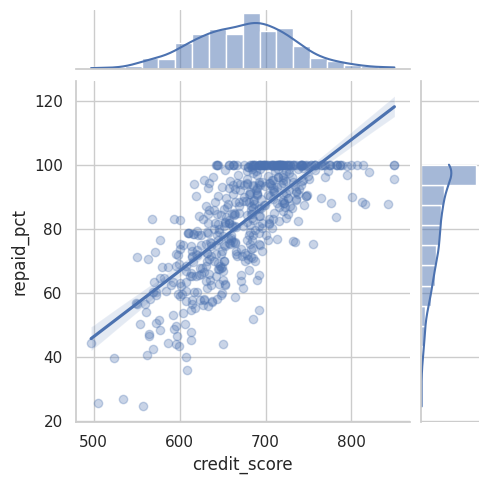

In [31]:
sns.jointplot(data=df, x="credit_score", y="repaid_pct", kind="reg",
              height=5, scatter_kws={"alpha": 0.3});

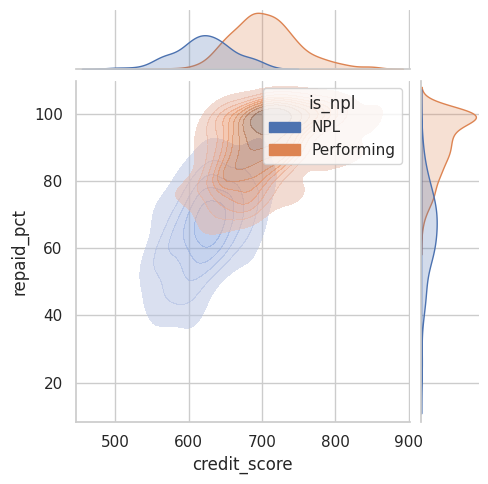

In [32]:
sns.jointplot(data=df, x="credit_score", y="repaid_pct", hue="is_npl",
              kind="kde", fill=True, alpha=0.5, height=5);

### 9.3 `FacetGrid` — Build Your Own Small Multiples

Figure-level functions use `FacetGrid` behind the scenes. Use it directly when you want to map **any** plotting function across panels.

1. Create the grid: `g = sns.FacetGrid(df, col=..., row=...)`
2. Map a function: `g.map_dataframe(sns.histplot, x=...)`
3. Tidy up: `g.set_titles()`, `g.set_axis_labels()`, `g.add_legend()`

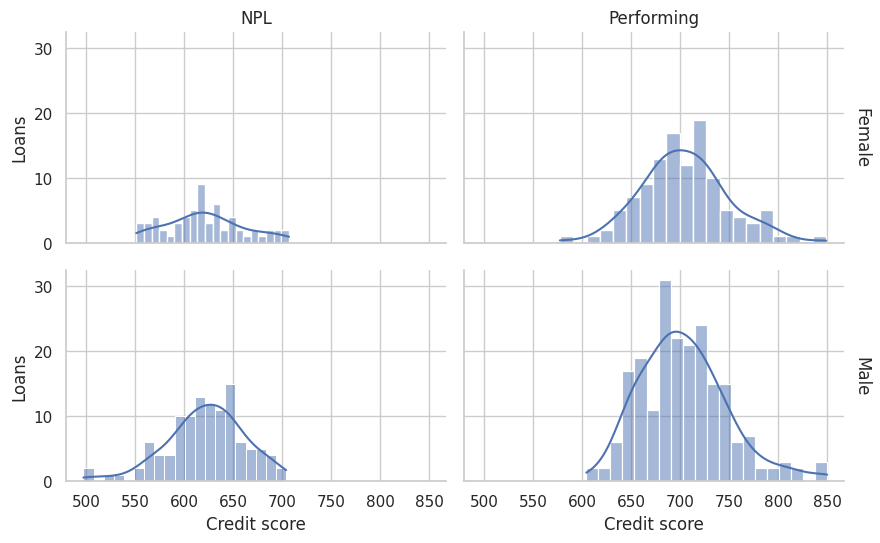

In [33]:
g = sns.FacetGrid(df, row="gender", col="is_npl", height=2.8, aspect=1.6, margin_titles=True)
g.map_dataframe(sns.histplot, x="credit_score", bins=20, kde=True)
g.set_axis_labels("Credit score", "Loans")
g.set_titles(col_template="{col_name}", row_template="{row_name}");

## 10. Customising Plots

Axes-level functions **return a Matplotlib `Axes`**; figure-level functions return a **`FacetGrid`** (use `g.ax` / `g.axes` to reach the Axes). After that, all Matplotlib customisation works.

| Task | Axes-level (`ax`) | Figure-level (`g`) |
|---|---|---|
| Title | `ax.set_title("…")` | `g.figure.suptitle("…", y=1.03)` |
| Axis labels | `ax.set(xlabel="…", ylabel="…")` | `g.set_axis_labels("…", "…")` |
| Limits | `ax.set(xlim=(0, 100))` | `g.set(xlim=(0, 100))` |
| Rotate ticks | `ax.tick_params(axis="x", rotation=45)` | `g.tick_params(axis="x", rotation=45)` |
| Legend position | `sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))` | `sns.move_legend(g, …)` |
| Remove spines | `sns.despine()` | `sns.despine()` |

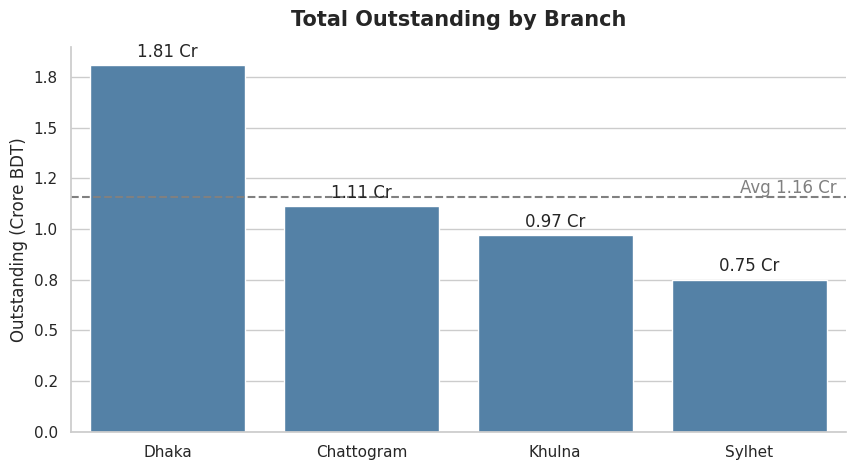

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

order = df.groupby("branch")["outstanding"].sum().sort_values(ascending=False).index
sns.barplot(data=df, x="branch", y="outstanding", estimator="sum", errorbar=None,
            order=order, color="steelblue", ax=ax)

# Title, labels, and number formatting
ax.set_title("Total Outstanding by Branch", fontsize=15, fontweight="bold", pad=15)
ax.set(xlabel="", ylabel="Outstanding (Crore BDT)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e7:.1f}")

# Value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v/1e7:.2f} Cr" for v in container.datavalues], padding=3)

# Reference line + text annotation
avg = df.groupby("branch")["outstanding"].sum().mean()
ax.axhline(avg, ls="--", color="gray")
ax.text(3.45, avg, f"Avg {avg/1e7:.2f} Cr", va="bottom", ha="right", color="gray")

sns.despine()

### 10.1 Custom colours

- A named palette: `palette="Set2"`
- A list: `palette=["#1f77b4", "#d62728"]`
- A **dictionary** — fixes a colour per category (consistent across every chart in a report)

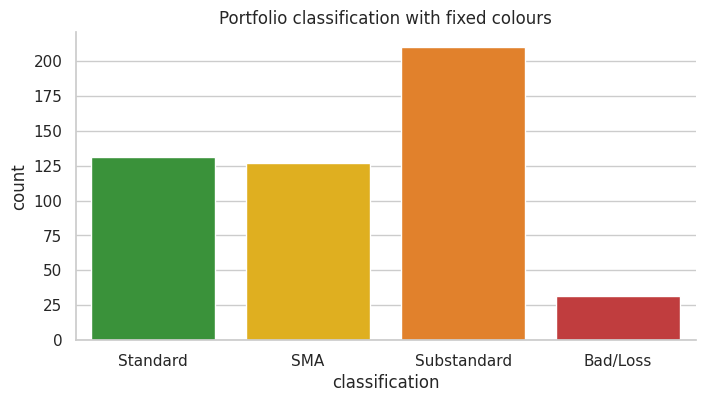

In [35]:
risk_colors = {"Standard": "#2ca02c", "SMA": "#ffbf00", "Substandard": "#ff7f0e", "Bad/Loss": "#d62728"}

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, x="classification", order=class_order,
              hue="classification", palette=risk_colors, legend=False, ax=ax)
ax.set_title("Portfolio classification with fixed colours")
sns.despine();

### 10.2 Dashboard layout with `plt.subplots`

Combine several axes-level plots into one figure — useful for reports.

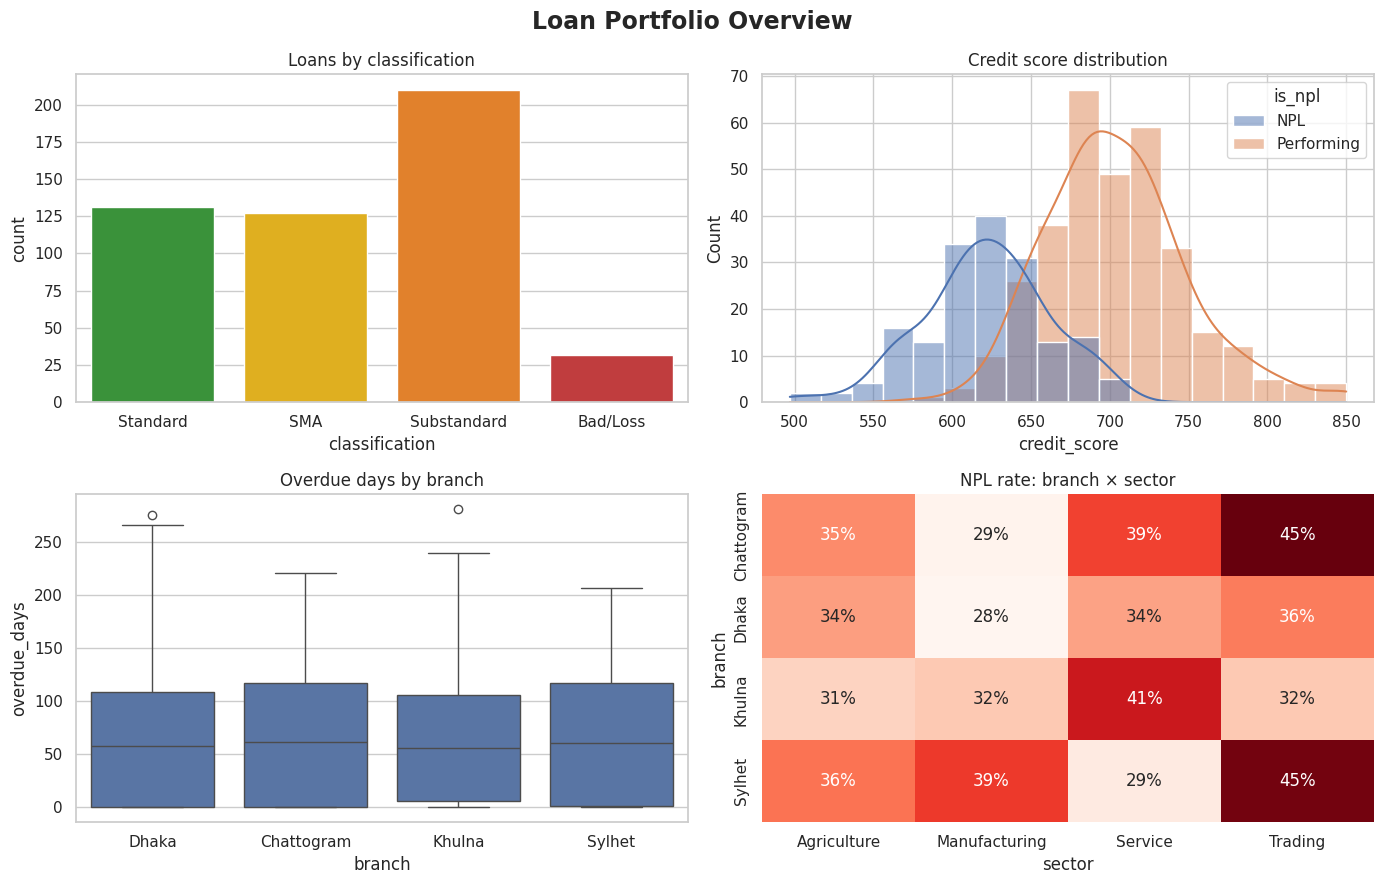

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Loan Portfolio Overview", fontsize=17, fontweight="bold")

sns.countplot(data=df, x="classification", order=class_order,
              hue="classification", palette=risk_colors, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Loans by classification")

sns.histplot(data=df, x="credit_score", hue="is_npl", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Credit score distribution")

sns.boxplot(data=df, x="branch", y="overdue_days", ax=axes[1, 0])
axes[1, 0].set_title("Overdue days by branch")

sns.heatmap(npl_rate, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("NPL rate: branch × sector")

plt.tight_layout()

## 11. Saving Figures

| Plot type | Save with |
|---|---|
| Axes-level | `plt.savefig("file.png", dpi=300, bbox_inches="tight")` or `fig.savefig(...)` |
| Figure-level | `g.savefig("file.png", dpi=300, bbox_inches="tight")` |

- `dpi=300` → print / slide quality
- `bbox_inches="tight"` → no clipped titles or legends
- Use `.svg` or `.pdf` for sharp vector graphics; `.png` for slides and documents
- Call `savefig` **before** `plt.show()`, otherwise the saved image is blank

In [37]:
fig.savefig("portfolio_overview.png", dpi=300, bbox_inches="tight")

g = sns.displot(data=df, x="repaid_pct", height=3, aspect=1.5)
g.savefig("repaid_distribution.png", dpi=150, bbox_inches="tight")
plt.close("all")
print("Saved!")

Saved!


## 12. Choosing the Right Plot

| Question | Data | Plot |
|---|---|---|
| How is one numeric variable distributed? | 1 numeric | `histplot`, `kdeplot`, `ecdfplot`, `boxplot` |
| How many in each category? | 1 categorical | `countplot` |
| How does a numeric value differ across groups? | numeric + categorical | `barplot` (mean), `boxplot` / `violinplot` (spread), `stripplot` (raw) |
| Are two numeric variables related? | 2 numeric | `scatterplot`, `regplot`, `jointplot` |
| How does something change over time? | time + numeric | `lineplot` |
| Which variables are correlated? | many numeric | `heatmap` of `df.corr()` |
| Quick look at everything? | many numeric | `pairplot` |
| Compare the same plot across groups? | any + category | `displot` / `catplot` / `relplot` with `col=` |
| Summary table as a picture? | pivot table | `heatmap` |

### Quick Reference

```python
import seaborn as sns; import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", palette="deep")

sns.histplot(data=df, x="col", hue="grp", kde=True)
sns.kdeplot(data=df, x="col", hue="grp", fill=True)
sns.countplot(data=df, x="cat", order=[...])
sns.barplot(data=df, x="cat", y="num", estimator="sum", errorbar=None)
sns.boxplot(data=df, x="cat", y="num", hue="grp")
sns.violinplot(data=df, x="cat", y="num", split=True, hue="grp")
sns.scatterplot(data=df, x="a", y="b", hue="grp", size="c")
sns.lineplot(data=df, x="date", y="num", hue="grp", marker="o")
sns.regplot(data=df, x="a", y="b")
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
sns.pairplot(df, hue="grp", corner=True)
sns.jointplot(data=df, x="a", y="b", kind="reg")
sns.catplot(data=df, x="cat", y="num", col="grp", kind="box")

ax.set_title("…"); ax.set(xlabel="…", ylabel="…"); sns.despine()
plt.savefig("fig.png", dpi=300, bbox_inches="tight")
```

## 13. Practice Exercises

1. Plot a histogram of `outstanding` using a log scale, split by `is_npl` with `multiple="dodge"`.
2. Create a `countplot` of loans by `sector`, ordered from most to fewest loans.
3. Use `barplot` to show the **median** `credit_score` per `classification` (in `class_order`), with standard-deviation error bars.
4. Draw a violin plot of `repaid_pct` by `sector`, overlaid with a `stripplot`.
5. Make a `scatterplot` of `loan_lakh` vs `repaid_pct`, coloured by `branch`, with points sized by `tenure_months`.
6. Plot the monthly **count** of NPL loans with `lineplot` (hint: `groupby` first).
7. Build a heatmap of the **average loan amount (lakh)** by `branch` × `tenure_months`, with annotations.
8. Use `lmplot` to compare the `credit_score` → `overdue_days` relationship across the four sectors.
9. Create a 1×3 dashboard: countplot, boxplot and scatterplot of your choice, with a figure title. Save it as a PNG at 300 dpi.
10. Apply `sns.set_theme(context="talk")` and redraw any plot — how does it change? When would you use it?